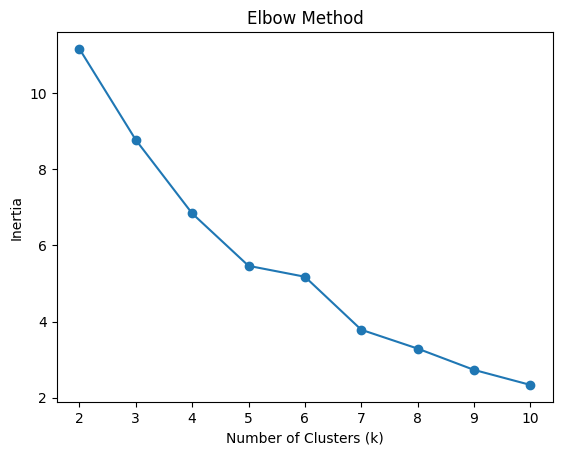

cluster
0    22141
1     4921
2        2
3       11
dtype: int64

Cluster: 0
                                  name  price  positive_ratings  \
appid                                                             
588140  ESCAPE FROM VOYNA: Dead Forest   4.79                 0   
705020               Bottom of the 9th   4.99                11   

        negative_ratings  average_playtime  
appid                                       
588140                 1                 0  
705020                 2                 0  

Cluster: 1
                         name  price  positive_ratings  negative_ratings  \
appid                                                                      
233610               Distance  19.49              3989               279   
1051890  BLOCKADE War Stories  11.39                11                 6   

         average_playtime  
appid                      
233610                887  
1051890                 0  

Cluster: 2
                                 

In [7]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

df = pd.read_csv("steam.csv", index_col="appid")

features = df[["price", "positive_ratings", "negative_ratings", "average_playtime"]]

features_norm = (features - features.min(axis=0)) / (
    features.max(axis=0) - features.min(axis=0)
)

inertias = []
k_values = range(2, 11)

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42)
    model.fit(features_norm)
    inertias.append(model.inertia_)

plt.plot(k_values, inertias, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

k = 4
model = KMeans(n_clusters=k, random_state=42)
clusters = model.fit_predict(features_norm)

cluster_df = pd.DataFrame(
    clusters, index=features_norm.index, columns=["cluster"]
)

print(cluster_df.groupby("cluster").size())

for cluster, games in cluster_df.groupby("cluster"):
    print("\nCluster:", cluster)
    print(df.loc[games.sample(n=2, random_state=42).index,
                 ["name", "price", "positive_ratings",
                  "negative_ratings", "average_playtime"]])
